In [1]:
import pandas as pd

In [2]:
# !pip install pyarrow

In [2]:
import datetime as dt
from sklearn.feature_extraction import DictVectorizer

In [3]:
import seaborn as sns
import matplotlib.pyplot as plt

In [4]:
import mlflow
# mlflow.set_tracking_uri("/workspaces/mlops-handson/mlflow.db")
mlflow.set_tracking_uri("sqlite:////workspaces/mlops-handson/mlflow.db")
mlflow.set_experiment("Mlops-handson")

<Experiment: artifact_location='/workspaces/mlops-handson/hands-on1/01 intro/mlruns/1', creation_time=1792576409997, effective_trace_archival_retention=None, experiment_id='1', last_update_time=1792576409997, lifecycle_stage='active', name='Mlops-handson', tags={}, trace_location=None, workspace='default'>

In [ ]:
# train_df = pd.read_parquet('data/yellow_tripdata_2021-02.parquet')

In [ ]:
# train_df.columns

In [9]:
# val_df = pd.read_parquet('data/yellow_tripdata_2021-02.parquet')

In [10]:
# val_df = val_df.rename(columns={'tpep_pickup_datetime': 'pickup_datetime', 'tpep_dropoff_datetime': 'dropoff_datetime'})

In [11]:
# train_df = train_df.rename(columns={'tpep_pickup_datetime': 'pickup_datetime', 'tpep_dropoff_datetime': 'dropoff_datetime'})

In [5]:
def read_dataframe(filename):
    df = pd.read_parquet(filename)

    df.lpep_dropoff_datetime = pd.to_datetime(df.tpep_dropoff_datetime)
    df.lpep_pickup_datetime = pd.to_datetime(df.tpep_pickup_datetime)

    df['duration'] = df.tpep_dropoff_datetime - df.tpep_pickup_datetime
    df.duration = df.duration.apply(lambda td: td.total_seconds() / 60)

    df = df[(df.duration >= 1) & (df.duration <= 60)]

    categorical = ['PULocationID', 'DOLocationID']
    df[categorical] = df[categorical].astype(str)
    
    return df

In [6]:
# train_df = inferance(train_df)
train_df = read_dataframe('data/yellow_tripdata_2021-02.parquet')


/tmp/ipykernel_17483/1010765739.py:4: UserWarning: Pandas doesn't allow columns to be created via a new attribute name - see https://pandas.pydata.org/pandas-docs/stable/indexing.html#attribute-access
  df.lpep_dropoff_datetime = pd.to_datetime(df.tpep_dropoff_datetime)
/tmp/ipykernel_17483/1010765739.py:5: UserWarning: Pandas doesn't allow columns to be created via a new attribute name - see https://pandas.pydata.org/pandas-docs/stable/indexing.html#attribute-access
  df.lpep_pickup_datetime = pd.to_datetime(df.tpep_pickup_datetime)


In [7]:
# train_df
val_df = read_dataframe('data/yellow_tripdata_2021-02.parquet')


/tmp/ipykernel_17483/1010765739.py:4: UserWarning: Pandas doesn't allow columns to be created via a new attribute name - see https://pandas.pydata.org/pandas-docs/stable/indexing.html#attribute-access
  df.lpep_dropoff_datetime = pd.to_datetime(df.tpep_dropoff_datetime)
/tmp/ipykernel_17483/1010765739.py:5: UserWarning: Pandas doesn't allow columns to be created via a new attribute name - see https://pandas.pydata.org/pandas-docs/stable/indexing.html#attribute-access
  df.lpep_pickup_datetime = pd.to_datetime(df.tpep_pickup_datetime)


In [8]:
# val_df = inferance(val_df)

In [8]:
categorical = ['PULocationID','DOLocationID']
numerical = ['trip_distance']


# categorical_value = ['PULocationID','DOLocationID']
# numerical = ['trip_distance']
# train_df[categorical_value] = train_df[categorical_value].astype(str)

# train_df['PU_DO'] = train_df['PULocationID'] + '_' + train_df['DOLocationID']

# categorical = ['PU_DO'] 
# numerical = ['trip_distance']

train_dicts = train_df[categorical+numerical].to_dict(orient = 'records')
dv = DictVectorizer()

X_train = dv.fit_transform(train_dicts)

target = 'duration'

Y_train = train_df[target].values


In [9]:
categorical = ['PULocationID','DOLocationID']
numerical = ['trip_distance']

# val_df[categorical_value] = val_df[categorical_value].astype(str)

# val_df ['PU_DO'] = val_df ['PULocationID'] + '_' + val_df ['DOLocationID']
val_dicts = val_df[categorical+numerical].to_dict(orient = 'records')
# dv = DictVectorizer()

X_val = dv.transform(val_dicts)
Y_val = val_df[target].values

In [18]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import root_mean_squared_error
with mlflow.start_run():
    mlflow.set_tag("model","LinearRegression")
    mlflow.log_param("train_data_path","data/yellow_tripdata_2021-01.parquet")
    mlflow.log_param("valid_data_path","data/yellow_tripdata_2021-02.parquet")
    model = LinearRegression()
    
    model.fit(X_train,Y_train)
    y_pred = model.predict(X_val)
    rmse = root_mean_squared_error(Y_val,y_pred)
    mlflow.log_metric("rmse",rmse)
    mlflow.log_artifact(local_path="model/lin_reg.bin", artifact_path="models_pickle")
    

In [19]:
y_pred = model.predict(X_val)

In [20]:
rmse = root_mean_squared_error(Y_val,y_pred)

In [21]:
rmse

7.360062854588416

/tmp/ipykernel_9654/4293836138.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(y_pred, label='prediction')
/tmp/ipykernel_9654/4293836138.py:2: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(Y_val, label='actual')


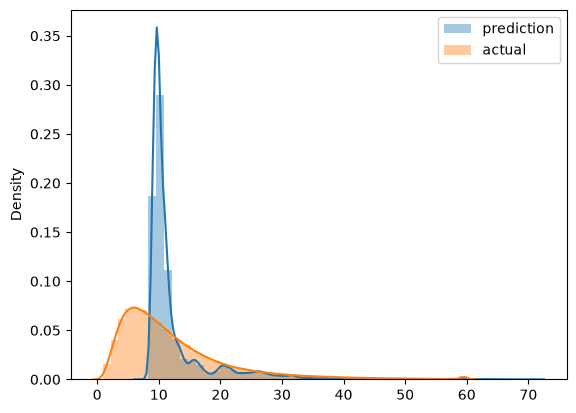

In [22]:
sns.distplot(y_pred, label='prediction')
sns.distplot(Y_val, label='actual')

plt.legend()

In [23]:
from sklearn.linear_model import Lasso
from sklearn.linear_model import Ridge

In [24]:
import numpy as np
from scipy import sparse

def to_int32(X):
    X = sparse.csc_matrix(X)          # Lasso works on CSC internally
    X.indices = X.indices.astype(np.int32)
    X.indptr = X.indptr.astype(np.int32)
    return X

X_train = to_int32(X_train)
X_val = to_int32(X_val)



lr = Lasso(0.01)
lr.fit(X_train, Y_train)

y_pred = lr.predict(X_val)

root_mean_squared_error(Y_val, y_pred)

7.715332561743763

In [25]:
import pickle

In [26]:
with open('model/lin_reg.bin', 'wb') as f_out:
    pickle.dump((dv, model), f_out)

In [27]:
with open('model/lin_reg.bin', 'wb') as f_out:
    pickle.dump((dv, lr), f_out)

In [10]:
import xgboost as xgb

In [11]:
from hyperopt import fmin, tpe, hp, STATUS_OK, Trials
from hyperopt.pyll import scope

In [12]:
# !pip install hyperopt


In [13]:
train  = xgb.DMatrix(X_train, label = Y_train)
val = xgb.DMatrix(X_val, label = Y_val)

In [14]:
def objective(params):
    with mlflow.start_run():
        mlflow.set_tag("model", "xgboost")
        mlflow.log_params(params)
        
        boost = xgb.train(
            params=params,
            dtrain=train,
            num_boost_round=1000,
            evals=[(val, 'validation')],  # Fixed: list containing the tuple
            early_stopping_rounds=50,
            verbose_eval=False            # Optional: keeps notebook output clean across 50 trials
        )
        
        y_pred = boost.predict(val)
        rmse = root_mean_squared_error(Y_val, y_pred)
        mlflow.log_metric("rmse", rmse)
        
    return {'loss': rmse, 'status': STATUS_OK}
        

In [ ]:
search_space = {
    'max_depth': scope.int(hp.quniform('max_depth', 4, 100, 1)),
    'learning_rate': hp.loguniform('learning_rate', -3, 0),
    'reg_alpha': hp.loguniform('reg_alpha', -5, -1),
    'reg_lambda': hp.loguniform('reg_lambda', -6, -1),
    'min_child_weight': hp.loguniform('min_child_weight', -1, 3),
    'objective': 'reg:linear',
    'seed': 42
}

best_result = fmin(
    fn = objective,
    space = search_space,
    algo = tpe.suggest,
    max_evals = 50,
    trials = Trials()
)

  0%|                                                                                             | 0/50 [00:00<?, ?trial/s, best loss=?]

/home/codespace/anaconda3/lib/python3.14/site-packages/xgboost/callback.py:385: UserWarning: [10:15:31] WARNING: /__w/xgboost/xgboost/src/objective/regression_obj.cu:275: reg:linear is now deprecated in favor of reg:squarederror.
  self.starting_round = model.num_boosted_rounds()

